# Full Pipeline Replication on an Independent Cohort — GSE37745



## 1. Imports and Environment Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, time, pickle, re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (roc_auc_score, f1_score, accuracy_score,
                             confusion_matrix, classification_report)
from scipy.stats import kruskal

import lightgbm as lgb
import xgboost as xgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def _pip(pkg):
    import subprocess, sys
    print(f"Installing {pkg} ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "--quiet"])

try:
    import shap
except ImportError:
    _pip("shap"); import shap
try:
    from lifelines import KaplanMeierFitter, CoxPHFitter
    from lifelines.statistics import logrank_test
except ImportError:
    _pip("lifelines")
    from lifelines import KaplanMeierFitter, CoxPHFitter
    from lifelines.statistics import logrank_test
try:
    import scikit_posthocs as sp
except ImportError:
    _pip("scikit-posthocs"); import scikit_posthocs as sp
from statsmodels.stats.multitest import multipletests

try:
    import tensorflow as tf
    from tensorflow import keras
    tf.get_logger().setLevel("ERROR")
    HAS_TF = True
except ImportError:
    HAS_TF = False
    print("[info] tensorflow not installed -> the CNN candidate will be skipped.")

sns.set_theme(style="whitegrid")
RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)
if HAS_TF:
    tf.random.set_seed(RANDOM_STATE)

DATA_DIR = "../data"
OUTPUT_DIR = "../results/gse37745_pipeline"
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Environment ready. TensorFlow available:", HAS_TF)

Environment ready. TensorFlow available: True


## 2. Configuration — identical to the TCGA pipeline

In [ ]:
PATHS = {"EXPR": os.path.join(DATA_DIR, "GSE37745_expression.csv"),
         "CLIN": os.path.join(DATA_DIR, "GSE37745_clinical.csv")}
for k, p in PATHS.items():
    print(f"{k:5s} -> {p}  {'OK' if os.path.exists(p) else 'NOT FOUND !!!'}")

QUICK_TEST_MODE = False   # True = tiny settings just to check the notebook runs end-to-end

N_CPU_THREADS = 2
if QUICK_TEST_MODE:
    N_COMPARISON_REPEATS, N_FINAL_REPEATS, N_TUNING_TRIALS = 3, 3, 5
    N_STABILITY_REPEATS, CNN_EPOCHS = 3, 5
    ADABOOST_N_ESTIMATORS, RF_N_ESTIMATORS = 20, 100
else:
    N_COMPARISON_REPEATS, N_FINAL_REPEATS, N_TUNING_TRIALS = 20, 30, 20
    N_STABILITY_REPEATS, CNN_EPOCHS = 20, 100
    ADABOOST_N_ESTIMATORS, RF_N_ESTIMATORS = 200, 500
N_TUNING_CV_FOLDS = 5
MAX_BOOST_ROUNDS, EARLY_STOPPING_ROUNDS = 500, 30
CORE_THRESHOLD = 80

# ---- TCGA reference results (from the original pipeline / methodology document) ----
TCGA_CORE_STABLE = ["KRT5", "KRT6A", "KRT6B", "KRT6C", "DSG3", "DSC3", "KRT14", "KRT13",
                    "S100A7", "SERPINB13", "CALML3", "CLCA2", "GSTM1", "MUC5B", "SPRR2A"]
TCGA_STAGE_TOP6 = ["KRT6C", "SPRR2A", "DSG3", "KRT6A", "KRT14", "DSC3"]
TCGA_REF = {"n_samples": 1017, "winning_model": "LogisticRegression",
            "final_acc": 0.9569, "final_acc_sd": 0.0173, "final_auc": 0.9884, "final_auc_sd": 0.0080,
            "n_core_stable": 15, "n_core_known_markers": 12, "stage_sig": "11/15",
            "univariate_sig": "KRT6A, DSG3, KRT6C", "cox_fdr_sig": "0/6"}
print(f"Config: comparison={N_COMPARISON_REPEATS}, final={N_FINAL_REPEATS}, "
      f"tuning trials={N_TUNING_TRIALS}, stability={N_STABILITY_REPEATS}")

EXPR  -> .\GSE37745_expression.csv  OK
CLIN  -> .\GSE37745_clinical.csv  OK
Config: comparison=20, final=30, tuning trials=20, stability=20


## 3. Data Loading — LUAD and LUSC only, all genes

In [3]:
expr = pd.read_csv(PATHS["EXPR"], index_col=0).T          # rows = samples, cols = genes
expr.index.name = "sampleID"
expr = expr.loc[:, ~expr.columns.duplicated()]
clin = pd.read_csv(PATHS["CLIN"], index_col=0)
clin = clin[clin["histology"].isin(["LUAD", "LUSC"])]

X = expr.loc[clin.index].astype(np.float32)
y = clin["histology"]
y_bin = (y == "LUSC").astype(int).values
X_vals = X.values
GENE_NAMES = np.array(X.columns)

print(f"Total: {len(X)} samples ({y.value_counts().to_dict()}), {X.shape[1]} genes (ALL genes used)")

Total: 172 samples ({'LUAD': 106, 'LUSC': 66}), 21655 genes (ALL genes used)


## 4. Exploratory Data Analysis (EDA)

=== Class balance ===
histology
LUAD    106
LUSC     66
Name: count, dtype: int64
Missing values in expression matrix: 0
Zero-variance genes: 0 / 21655


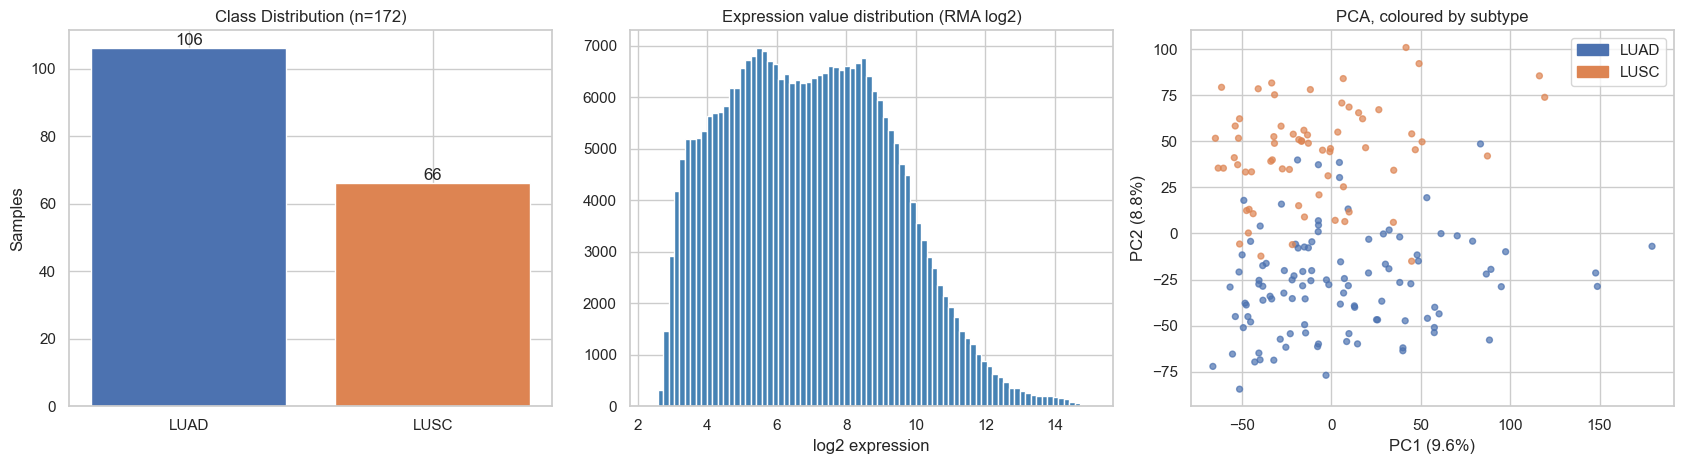

In [4]:
print("=== Class balance ===")
print(y.value_counts())
print(f"Missing values in expression matrix: {X.isna().sum().sum()}")
gene_var = X.var(axis=0)
print(f"Zero-variance genes: {(gene_var == 0).sum()} / {len(gene_var)}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
vc = y.value_counts().reindex(["LUAD", "LUSC"])
axes[0].bar(vc.index, vc.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(vc.values):
    axes[0].text(i, v + 1, str(v), ha="center")
axes[0].set_title(f"Class Distribution (n={len(y)})"); axes[0].set_ylabel("Samples")

rng = np.random.RandomState(RANDOM_STATE)
flat = X_vals.flatten()
axes[1].hist(flat[rng.choice(len(flat), min(300_000, len(flat)), replace=False)],
             bins=80, color="steelblue", edgecolor="white")
axes[1].set_title("Expression value distribution (RMA log2)"); axes[1].set_xlabel("log2 expression")

Xp = PCA(n_components=2, random_state=RANDOM_STATE).fit(StandardScaler().fit_transform(X_vals))
P = Xp.transform(StandardScaler().fit_transform(X_vals))
axes[2].scatter(P[:, 0], P[:, 1], c=y.map({"LUAD": "#4C72B0", "LUSC": "#DD8452"}), s=18, alpha=.7)
axes[2].set_xlabel(f"PC1 ({Xp.explained_variance_ratio_[0]*100:.1f}%)")
axes[2].set_ylabel(f"PC2 ({Xp.explained_variance_ratio_[1]*100:.1f}%)")
axes[2].set_title("PCA, coloured by subtype")
axes[2].legend(handles=[mpatches.Patch(color="#4C72B0", label="LUAD"),
                        mpatches.Patch(color="#DD8452", label="LUSC")])
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/eda_overview.png", dpi=150); plt.show()

## 5. Model Comparison — 7 models across 20 random 80/10/10 splits (same as TCGA)

In [5]:
def get_fresh_models():
    return {
        "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
        "LinearSVM": LinearSVC(class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE),
        "RandomForest": RandomForestClassifier(n_estimators=RF_N_ESTIMATORS, class_weight="balanced_subsample",
                                               random_state=RANDOM_STATE, n_jobs=-1),
        "AdaBoost": AdaBoostClassifier(n_estimators=ADABOOST_N_ESTIMATORS, random_state=RANDOM_STATE),
    }

def fit_predict_sklearn(model, Xtr, ytr, Xte):
    model.fit(Xtr, ytr)
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(Xte)[:, 1]
    else:
        scores = model.decision_function(Xte)
        proba = (scores - scores.min()) / (scores.max() - scores.min() + 1e-9)
    return proba, (proba >= 0.5).astype(int)

def fit_predict_xgb(Xtr, ytr, Xva, yva, Xte):
    m = xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.08, tree_method="hist",
                          max_bin=63, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=N_CPU_THREADS)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    proba = m.predict_proba(Xte)[:, 1]
    return proba, (proba >= 0.5).astype(int)

def fit_predict_lgb(Xtr, ytr, Xva, yva, Xte, params=None):
    train_ds = lgb.Dataset(Xtr, label=ytr, params={"max_bin": 63, "feature_pre_filter": False})
    val_ds = lgb.Dataset(Xva, label=yva, reference=train_ds)
    p = params or {"objective": "binary", "metric": "auc", "verbose": -1, "num_threads": N_CPU_THREADS,
                   "max_bin": 63, "num_leaves": 31, "learning_rate": 0.08, "max_depth": 4}
    bst = lgb.train(p, train_ds, num_boost_round=300, valid_sets=[val_ds],
                    callbacks=[lgb.early_stopping(20, verbose=False)])
    proba = bst.predict(Xte)
    return proba, (proba >= 0.5).astype(int)

def build_cnn(n_features):
    model = keras.Sequential([
        keras.layers.Input(shape=(n_features, 1)),
        keras.layers.Conv1D(16, kernel_size=5, activation="relu"),
        keras.layers.Flatten(),
        keras.layers.Dropout(0.4),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="binary_crossentropy", metrics=["AUC"])
    return model

def fit_predict_cnn(Xtr, ytr, Xva, yva, Xte):
    sc = StandardScaler().fit(Xtr)
    Xtr_s, Xva_s, Xte_s = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)
    model = build_cnn(Xtr_s.shape[1])
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    model.fit(Xtr_s[..., None], ytr, validation_data=(Xva_s[..., None], yva),
              epochs=CNN_EPOCHS, batch_size=16, callbacks=[es], verbose=0)
    proba = model.predict(Xte_s[..., None], verbose=0).flatten()
    return proba, (proba >= 0.5).astype(int)

def split_801010(seed):
    Xtr, Xtemp, ytr, ytemp = train_test_split(X_vals, y_bin, test_size=0.2, random_state=seed, stratify=y_bin)
    Xva, Xte, yva, yte = train_test_split(Xtemp, ytemp, test_size=0.5, random_state=seed, stratify=ytemp)
    return Xtr, Xva, Xte, ytr, yva, yte

print("Model-building functions defined.")

Model-building functions defined.


In [6]:
comparison_ckpt = os.path.join(OUTPUT_DIR, "checkpoint_model_comparison.pkl")
if os.path.exists(comparison_ckpt):
    with open(comparison_ckpt, "rb") as f:
        comparison_long_df = pickle.load(f)
    print(f"Checkpoint found -> loaded {len(comparison_long_df)} rows (delete the file to re-run).")
else:
    rows, t0 = [], time.time()
    for seed in range(N_COMPARISON_REPEATS):
        Xtr, Xva, Xte, ytr, yva, yte = split_801010(seed)
        results = {}
        for name, model in get_fresh_models().items():
            results[name] = fit_predict_sklearn(model, Xtr, ytr, Xte)
        results["XGBoost"] = fit_predict_xgb(Xtr, ytr, Xva, yva, Xte)
        results["LightGBM"] = fit_predict_lgb(Xtr, ytr, Xva, yva, Xte)
        if HAS_TF:
            results["CNN (Conv1D)"] = fit_predict_cnn(Xtr, ytr, Xva, yva, Xte)
        for name, (proba, pred) in results.items():
            rows.append({"seed": seed, "Model": name, "AUC": roc_auc_score(yte, proba),
                         "Accuracy": accuracy_score(yte, pred), "F1": f1_score(yte, pred)})
        print(f"  repeat {seed+1}/{N_COMPARISON_REPEATS} done ({time.time()-t0:.1f}s)")
    comparison_long_df = pd.DataFrame(rows)
    with open(comparison_ckpt, "wb") as f:
        pickle.dump(comparison_long_df, f)

  repeat 1/20 done (160.4s)
  repeat 2/20 done (296.6s)
  repeat 3/20 done (428.1s)
  repeat 4/20 done (567.2s)
  repeat 5/20 done (695.2s)
  repeat 6/20 done (841.7s)
  repeat 7/20 done (982.1s)
  repeat 8/20 done (1116.6s)
  repeat 9/20 done (1277.7s)
  repeat 10/20 done (1412.0s)
  repeat 11/20 done (1544.1s)
  repeat 12/20 done (1675.7s)
  repeat 13/20 done (1858.7s)
  repeat 14/20 done (2030.8s)
  repeat 15/20 done (2213.2s)
  repeat 16/20 done (2351.8s)
  repeat 17/20 done (2519.8s)
  repeat 18/20 done (2651.4s)
  repeat 19/20 done (2779.3s)
  repeat 20/20 done (2954.1s)


=== MODEL COMPARISON on GSE37745 -- averaged over 20 splits ===
             Model  Mean_Accuracy  Std_Accuracy  Mean_AUC  Std_AUC  Mean_F1
LogisticRegression         0.9667        0.0332    0.9825   0.0363   0.9564
         LinearSVM         0.9583        0.0355    0.9831   0.0353   0.9458
          AdaBoost         0.9528        0.0414    0.9857   0.0259   0.9372
      RandomForest         0.9528        0.0373    0.9873   0.0219   0.9359
      CNN (Conv1D)         0.9528        0.0519    0.9760   0.0399   0.9375
           XGBoost         0.9472        0.0381    0.9753   0.0360   0.9281
          LightGBM         0.7861        0.1655    0.9468   0.0577   0.4991

>>> WINNING MODEL: LogisticRegression (TCGA winner was LogisticRegression)


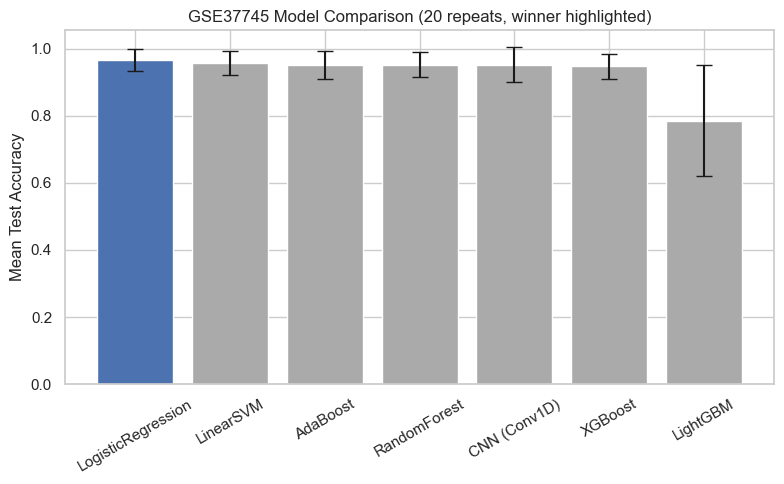

In [7]:
summary_df = (comparison_long_df.groupby("Model")
              .agg(Mean_Accuracy=("Accuracy", "mean"), Std_Accuracy=("Accuracy", "std"),
                   Mean_AUC=("AUC", "mean"), Std_AUC=("AUC", "std"), Mean_F1=("F1", "mean"))
              .fillna(0).sort_values("Mean_Accuracy", ascending=False).reset_index())
print(f"=== MODEL COMPARISON on GSE37745 -- averaged over {N_COMPARISON_REPEATS} splits ===")
print(summary_df.round(4).to_string(index=False))

WINNING_MODEL = summary_df.iloc[0]["Model"]
print(f"\n>>> WINNING MODEL: {WINNING_MODEL} "
      f"(TCGA winner was {TCGA_REF['winning_model']})")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(summary_df["Model"], summary_df["Mean_Accuracy"], yerr=summary_df["Std_Accuracy"], capsize=6,
       color=["#4C72B0" if m == WINNING_MODEL else "#AAAAAA" for m in summary_df["Model"]])
ax.set_ylabel("Mean Test Accuracy"); ax.tick_params(axis="x", rotation=30)
ax.set_title(f"GSE37745 Model Comparison ({N_COMPARISON_REPEATS} repeats, winner highlighted)")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/model_comparison.png", dpi=150); plt.show()
comparison_long_df.to_csv(f"{OUTPUT_DIR}/model_comparison_raw.csv", index=False)
summary_df.to_csv(f"{OUTPUT_DIR}/model_comparison_summary.csv", index=False)

### 5.1 Model used for SHAP


In [8]:
SHAP_SUPPORTED = ["LogisticRegression", "LinearSVM", "RandomForest", "XGBoost", "LightGBM"]
if WINNING_MODEL in SHAP_SUPPORTED:
    SHAP_MODEL = WINNING_MODEL
else:
    SHAP_MODEL = next(m for m in summary_df["Model"] if m in SHAP_SUPPORTED)
    print(f"[note] {WINNING_MODEL} has no fast exact SHAP explainer -> using next-best model "
          f"{SHAP_MODEL} for SHAP/stability.")
print("Model that will be tuned and explained:", SHAP_MODEL)

Model that will be tuned and explained: LogisticRegression


## 6. Hyperparameter Tuning (Optuna, same search spaces as TCGA)

In [9]:
Xtr_tune, Xva_tune, Xte_tune, ytr_tune, yva_tune, yte_tune = split_801010(RANDOM_STATE)
TUNE_MODEL = SHAP_MODEL
t0 = time.time()

if TUNE_MODEL == "LightGBM":
    train_ds = lgb.Dataset(Xtr_tune, label=ytr_tune, params={"max_bin": 63, "feature_pre_filter": False})
    def objective(trial):
        params = {"objective": "binary", "metric": "auc", "verbose": -1, "num_threads": N_CPU_THREADS,
                  "max_bin": 63,
                  "num_leaves": trial.suggest_int("num_leaves", 7, 63),
                  "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
                  "max_depth": trial.suggest_int("max_depth", 3, 7),
                  "min_child_samples": trial.suggest_int("min_child_samples", 5, 30),
                  "feature_fraction": trial.suggest_float("feature_fraction", 0.3, 1.0)}
        cv_result = lgb.cv(params, train_ds, num_boost_round=150, nfold=N_TUNING_CV_FOLDS, stratified=True,
                           seed=RANDOM_STATE, callbacks=[lgb.early_stopping(15, verbose=False)])
        return max(cv_result["valid auc-mean"])
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TUNING_TRIALS)
    tuned_params = dict(study.best_params)
    tuned_params.update({"objective": "binary", "metric": "auc", "verbose": -1,
                         "num_threads": N_CPU_THREADS, "max_bin": 63})

elif TUNE_MODEL == "XGBoost":
    def objective(trial):
        params = {"n_estimators": trial.suggest_int("n_estimators", 100, 400),
                  "max_depth": trial.suggest_int("max_depth", 3, 7),
                  "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
                  "subsample": trial.suggest_float("subsample", 0.6, 1.0),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
                  "tree_method": "hist", "max_bin": 63, "eval_metric": "logloss",
                  "random_state": RANDOM_STATE, "n_jobs": N_CPU_THREADS}
        m = xgb.XGBClassifier(**params)
        m.fit(Xtr_tune, ytr_tune, eval_set=[(Xva_tune, yva_tune)], verbose=False)
        return roc_auc_score(yva_tune, m.predict_proba(Xva_tune)[:, 1])
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TUNING_TRIALS)
    tuned_params = dict(study.best_params)
    tuned_params.update({"tree_method": "hist", "max_bin": 63, "eval_metric": "logloss",
                         "random_state": RANDOM_STATE, "n_jobs": N_CPU_THREADS})

elif TUNE_MODEL == "RandomForest":
    def objective(trial):
        params = {"n_estimators": trial.suggest_int("n_estimators", 100, 600),
                  "max_depth": trial.suggest_int("max_depth", 4, 30),
                  "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 10),
                  "max_features": trial.suggest_float("max_features", 0.1, 0.8),
                  "class_weight": "balanced_subsample", "random_state": RANDOM_STATE, "n_jobs": -1}
        m = RandomForestClassifier(**params).fit(Xtr_tune, ytr_tune)
        return roc_auc_score(yva_tune, m.predict_proba(Xva_tune)[:, 1])
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TUNING_TRIALS)
    tuned_params = dict(study.best_params)
    tuned_params.update({"class_weight": "balanced_subsample", "random_state": RANDOM_STATE, "n_jobs": -1})

else:  # LogisticRegression / LinearSVM
    def objective(trial):
        C = trial.suggest_float("C", 1e-4, 10.0, log=True)
        if TUNE_MODEL == "LogisticRegression":
            m = LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(Xtr_tune, ytr_tune)
            proba = m.predict_proba(Xva_tune)[:, 1]
        else:
            m = LinearSVC(C=C, class_weight="balanced", max_iter=8000, random_state=RANDOM_STATE).fit(Xtr_tune, ytr_tune)
            s = m.decision_function(Xva_tune)
            proba = (s - s.min()) / (s.max() - s.min() + 1e-9)
        return roc_auc_score(yva_tune, proba)
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=N_TUNING_TRIALS)
    tuned_params = {"C": study.best_params["C"]}

print(f"Best params for {TUNE_MODEL}: {tuned_params}")
print(f"Tuning completed in {time.time()-t0:.1f}s")

Best params for LogisticRegression: {'C': 0.05547119471592124}
Tuning completed in 16.4s


## 7. Final Robustness Evaluation — tuned model across 30 fresh splits

In [10]:
def make_tuned_model():
    if TUNE_MODEL == "LogisticRegression":
        return LogisticRegression(C=tuned_params["C"], max_iter=3000, class_weight="balanced")
    if TUNE_MODEL == "LinearSVM":
        return LinearSVC(C=tuned_params["C"], class_weight="balanced", max_iter=8000, random_state=RANDOM_STATE)
    if TUNE_MODEL == "RandomForest":
        return RandomForestClassifier(**tuned_params)
    if TUNE_MODEL == "XGBoost":
        return xgb.XGBClassifier(**tuned_params)
    return None   # LightGBM handled separately

def train_tuned(Xtr, ytr, Xva, yva):
    if TUNE_MODEL == "LightGBM":
        tr = lgb.Dataset(Xtr, label=ytr, params={"max_bin": 63, "feature_pre_filter": False})
        va = lgb.Dataset(Xva, label=yva, reference=tr)
        return lgb.train(tuned_params, tr, num_boost_round=MAX_BOOST_ROUNDS, valid_sets=[va],
                         callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False)])
    m = make_tuned_model()
    if TUNE_MODEL == "XGBoost":
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    else:
        m.fit(Xtr, ytr)
    return m

def predict_proba_any(m, Xte):
    if TUNE_MODEL == "LightGBM":
        return m.predict(Xte)
    if hasattr(m, "predict_proba"):
        return m.predict_proba(Xte)[:, 1]
    s = m.decision_function(Xte)
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

final_aucs, final_accs = [], []
all_y_true, all_y_pred, all_y_proba = [], [], []
t1 = time.time()
for seed in range(N_FINAL_REPEATS):
    Xtr, Xva, Xte, ytr, yva, yte = split_801010(seed)
    m = train_tuned(Xtr, ytr, Xva, yva)
    proba = predict_proba_any(m, Xte); pred = (proba >= 0.5).astype(int)
    final_aucs.append(roc_auc_score(yte, proba)); final_accs.append(accuracy_score(yte, pred))
    all_y_true.append(yte); all_y_pred.append(pred); all_y_proba.append(proba)
print(f"{N_FINAL_REPEATS} final repeats done in {time.time()-t1:.1f}s")
all_y_true, all_y_pred, all_y_proba = map(np.concatenate, (all_y_true, all_y_pred, all_y_proba))

mean_acc, std_acc = np.mean(final_accs), np.std(final_accs)
mean_auc, std_auc = np.mean(final_aucs), np.std(final_aucs)
print("=" * 60)
print(f"FINAL RESULT on GSE37745 -- {TUNE_MODEL} (tuned)")
print("=" * 60)
print(f"Mean Accuracy ({N_FINAL_REPEATS} repeats): {mean_acc*100:.2f}% +- {std_acc*100:.2f}%")
print(f"Mean AUC      ({N_FINAL_REPEATS} repeats): {mean_auc:.4f} +- {std_auc:.4f}")
print(f"TCGA reference: {TCGA_REF['final_acc']*100:.2f}% +- {TCGA_REF['final_acc_sd']*100:.2f}%, "
      f"AUC {TCGA_REF['final_auc']:.4f} +- {TCGA_REF['final_auc_sd']:.4f}")

30 final repeats done in 34.9s
FINAL RESULT on GSE37745 -- LogisticRegression (tuned)
Mean Accuracy (30 repeats): 95.19% +- 4.48%
Mean AUC      (30 repeats): 0.9844 +- 0.0297
TCGA reference: 95.69% +- 1.73%, AUC 0.9884 +- 0.0080


Pooled: 540 predictions | Accuracy=95.19% | AUC=0.9805
              precision    recall  f1-score   support

        LUAD     0.9524    0.9697    0.9610       330
        LUSC     0.9510    0.9238    0.9372       210

    accuracy                         0.9519       540
   macro avg     0.9517    0.9468    0.9491       540
weighted avg     0.9518    0.9519    0.9517       540



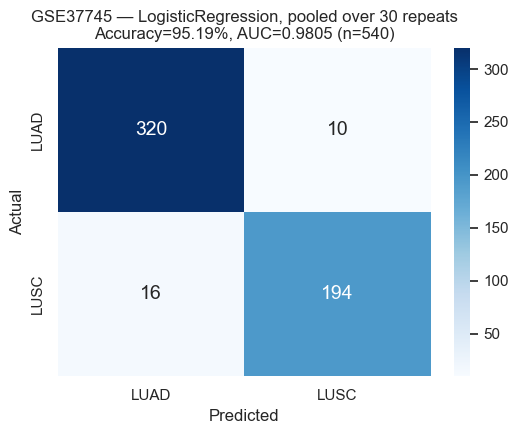

In [11]:
pooled_acc = accuracy_score(all_y_true, all_y_pred)
pooled_auc = roc_auc_score(all_y_true, all_y_proba)
print(f"Pooled: {len(all_y_true)} predictions | Accuracy={pooled_acc*100:.2f}% | AUC={pooled_auc:.4f}")
print(classification_report(all_y_true, all_y_pred, target_names=["LUAD", "LUSC"], digits=4))

cm = confusion_matrix(all_y_true, all_y_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["LUAD", "LUSC"],
            yticklabels=["LUAD", "LUSC"], ax=ax, annot_kws={"size": 14})
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title(f"GSE37745 — {TUNE_MODEL}, pooled over {N_FINAL_REPEATS} repeats\n"
             f"Accuracy={pooled_acc*100:.2f}%, AUC={pooled_auc:.4f} (n={len(all_y_true)})")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/final_confusion_matrix.png", dpi=150); plt.show()

## 8. Part B — SHAP biomarker discovery on GSE37745

Top 20 SHAP genes on GSE37745 (LogisticRegression):
 rank      gene  mean_abs_shap
    1     KRT6A       0.083733
    2     CLCA2       0.079946
    3  SERPINB5       0.060146
    4      KRT5       0.053594
    5    SPINK1       0.052422
    6      TP63       0.048870
    7      DSC3       0.048714
    8     SFTA3       0.045665
    9 SERPINB13       0.043029
   10    SPRR1B       0.042234
   11    TRIM29       0.037762
   12     SFTA2       0.036551
   13      NRN1       0.036381
   14     NTRK2       0.035215
   15    S100A7       0.033350
   16  SERPINB3       0.031368
   17       FGG       0.031208
   18      AGR3       0.031054
   19  SERPINB4       0.030549
   20    BPIFB1       0.030349


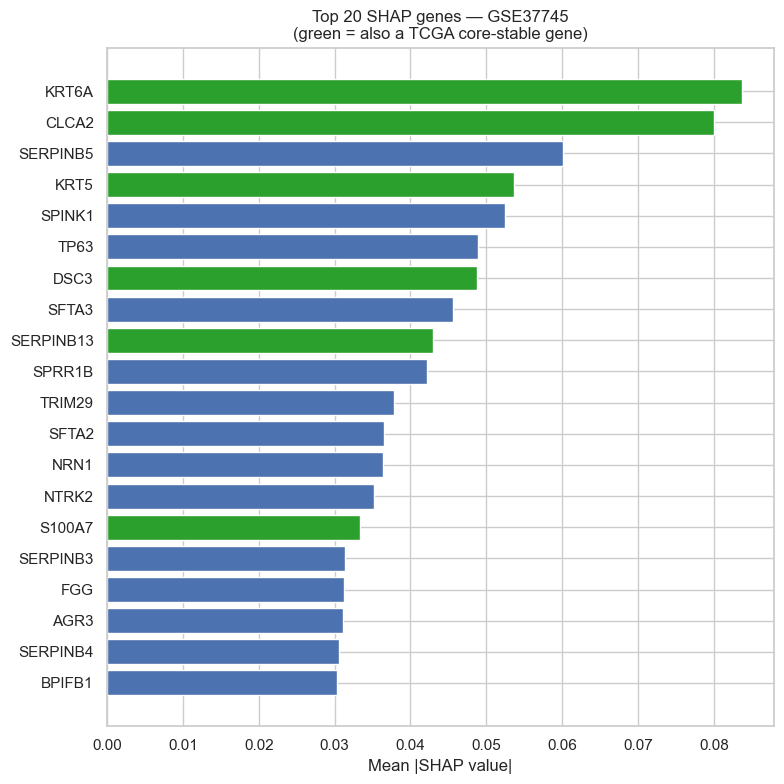

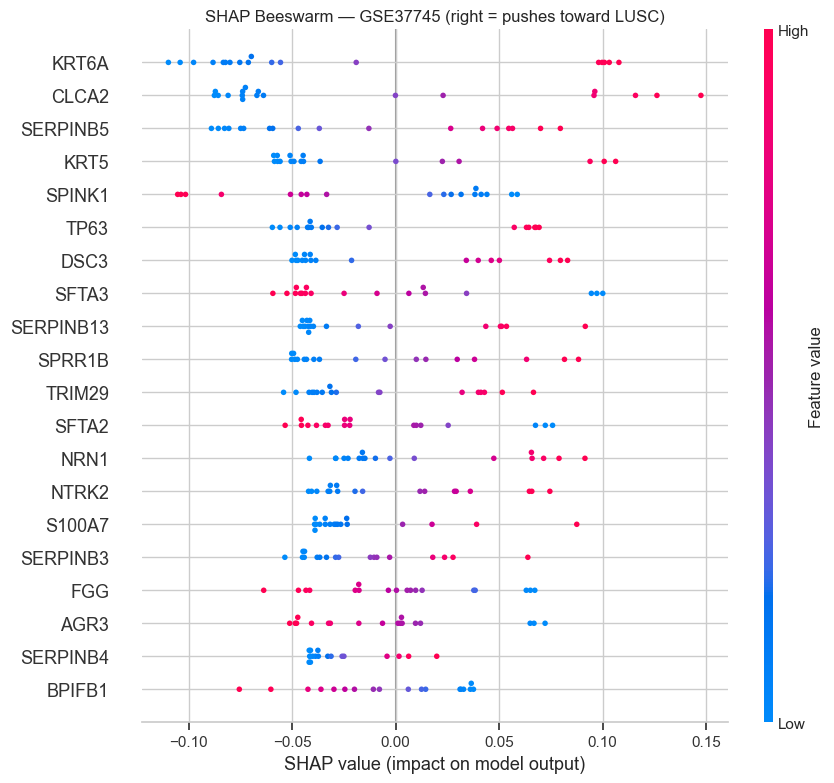

In [12]:
def shap_values_for(m, Xbg, Xexplain):
    if TUNE_MODEL in ("LogisticRegression", "LinearSVM"):
        sv = shap.LinearExplainer(m, Xbg).shap_values(Xexplain)
    else:
        sv = shap.TreeExplainer(m).shap_values(Xexplain)
    if isinstance(sv, list):
        sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3:            # some shap versions return (n, features, classes)
        sv = sv[:, :, 1]
    return sv

Xtr_xai, Xva_xai, Xte_xai, ytr_xai, yva_xai, yte_xai = split_801010(RANDOM_STATE)
xai_model = train_tuned(Xtr_xai, ytr_xai, Xva_xai, yva_xai)
shap_values = shap_values_for(xai_model, Xtr_xai, Xte_xai)
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({"gene": GENE_NAMES, "mean_abs_shap": mean_abs_shap}) \
    .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
shap_importance_df["rank"] = np.arange(1, len(shap_importance_df) + 1)
shap_importance_df.to_csv(f"{OUTPUT_DIR}/shap_gene_importance_full.csv", index=False)

top_n = 20
top_idx = np.argsort(mean_abs_shap)[::-1][:top_n]
top_genes = GENE_NAMES[top_idx]
print(f"Top {top_n} SHAP genes on GSE37745 ({TUNE_MODEL}):")
print(shap_importance_df.head(top_n)[["rank", "gene", "mean_abs_shap"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(range(top_n), mean_abs_shap[top_idx][::-1],
        color=["#2ca02c" if g in TCGA_CORE_STABLE else "#4C72B0" for g in top_genes[::-1]])
ax.set_yticks(range(top_n)); ax.set_yticklabels(top_genes[::-1])
ax.set_xlabel("Mean |SHAP value|")
ax.set_title("Top 20 SHAP genes — GSE37745\n(green = also a TCGA core-stable gene)")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/shap_top_genes_bar.png", dpi=150); plt.show()

shap.summary_plot(shap_values[:, top_idx], Xte_xai[:, top_idx], feature_names=list(top_genes),
                  show=False, max_display=top_n)
plt.gcf().set_size_inches(9, 8)
plt.title("SHAP Beeswarm — GSE37745 (right = pushes toward LUSC)")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/shap_beeswarm.png", dpi=150); plt.show()

In [13]:
KNOWN_LUAD_MARKERS = ["NAPSA", "NKX2-1", "TTF1", "SFTPC", "SFTPB", "MUC5B", "NAPSA1"]
KNOWN_LUSC_MARKERS = ["TP63", "KRT5", "KRT6A", "KRT6B", "SOX2", "DSG3", "TP73L"]
KNOWN_MARKERS = set(KNOWN_LUAD_MARKERS) | set(KNOWN_LUSC_MARKERS)

overlap = [g for g in top_genes if g in KNOWN_MARKERS]
print(f"{len(overlap)} of the top {top_n} SHAP genes are known clinical markers: {overlap}\n")
rank_lookup = dict(zip(shap_importance_df["gene"], shap_importance_df["rank"]))
print(f"Rank of each known marker among {len(GENE_NAMES)} genes:")
for g in KNOWN_LUAD_MARKERS + KNOWN_LUSC_MARKERS:
    print(f"  {g:7s}: {'#'+str(rank_lookup[g]) if g in rank_lookup else 'not on array'}")

3 of the top 20 SHAP genes are known clinical markers: ['KRT6A', 'KRT5', 'TP63']

Rank of each known marker among 21655 genes:
  NAPSA  : #52
  NKX2-1 : #22
  TTF1   : #14938
  SFTPC  : #254
  SFTPB  : #47
  MUC5B  : #181
  NAPSA1 : not on array
  TP63   : #6
  KRT5   : #4
  KRT6A  : #1
  KRT6B  : #24
  SOX2   : #119
  DSG3   : #40
  TP73L  : not on array


## 9. Part C — SHAP stability (20 splits) and overlap with TCGA core-stable genes

  repeat 1/20 done (1.1s)
  repeat 2/20 done (2.8s)
  repeat 3/20 done (4.1s)
  repeat 4/20 done (5.6s)
  repeat 5/20 done (6.6s)
  repeat 6/20 done (7.7s)
  repeat 7/20 done (8.9s)
  repeat 8/20 done (10.3s)
  repeat 9/20 done (11.1s)
  repeat 10/20 done (11.9s)
  repeat 11/20 done (12.8s)
  repeat 12/20 done (14.0s)
  repeat 13/20 done (15.1s)
  repeat 14/20 done (16.4s)
  repeat 15/20 done (17.7s)
  repeat 16/20 done (19.1s)
  repeat 17/20 done (20.4s)
  repeat 18/20 done (21.4s)
  repeat 19/20 done (22.3s)
  repeat 20/20 done (23.4s)
     gene  times_in_top20  stability_pct  in_TCGA_core
    CLCA2              20          100.0          True
     DSC3              20          100.0          True
     KRT5              20          100.0          True
    KRT6A              20          100.0          True
SERPINB13              20          100.0          True
 SERPINB5              20          100.0         False
     TP63              20          100.0         False
   TRIM29       

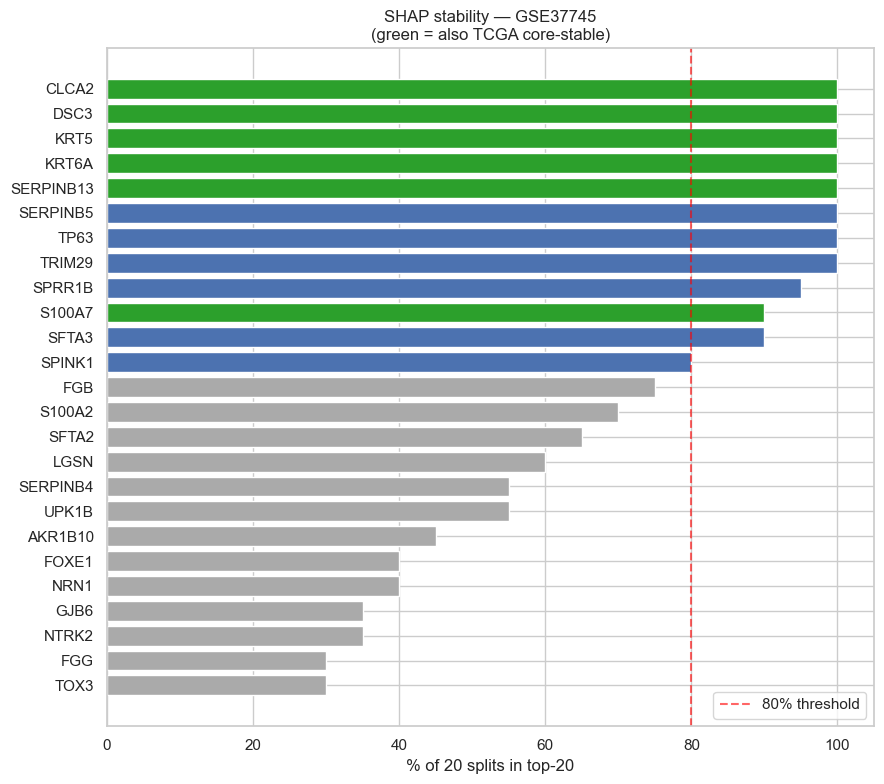

In [14]:
stab_ckpt = os.path.join(OUTPUT_DIR, "checkpoint_shap_stability.pkl")
if os.path.exists(stab_ckpt):
    with open(stab_ckpt, "rb") as f:
        all_top20_lists = pickle.load(f)
    print(f"Checkpoint found -> {len(all_top20_lists)} repeats loaded.")
else:
    all_top20_lists, t0 = [], time.time()
    for seed in range(N_STABILITY_REPEATS):
        Xtr_s, Xva_s, Xte_s, ytr_s, yva_s, yte_s = split_801010(seed)
        m = train_tuned(Xtr_s, ytr_s, Xva_s, yva_s)
        sv = shap_values_for(m, Xtr_s, Xte_s)
        top20 = GENE_NAMES[np.argsort(np.abs(sv).mean(axis=0))[::-1][:20]]
        all_top20_lists.append(list(top20))
        print(f"  repeat {seed+1}/{N_STABILITY_REPEATS} done ({time.time()-t0:.1f}s)")
    with open(stab_ckpt, "wb") as f:
        pickle.dump(all_top20_lists, f)

gene_frequency = Counter()
for lst in all_top20_lists:
    gene_frequency.update(set(lst))
n_rep = len(all_top20_lists)
stability_df = pd.DataFrame([{"gene": g, "times_in_top20": c, "stability_pct": c / n_rep * 100}
                             for g, c in gene_frequency.items()]) \
    .sort_values(["stability_pct", "gene"], ascending=[False, True]).reset_index(drop=True)
stability_df["in_TCGA_core"] = stability_df["gene"].isin(TCGA_CORE_STABLE)
stability_df.to_csv(f"{OUTPUT_DIR}/shap_gene_stability.csv", index=False)

core_stable_genes = stability_df[stability_df["stability_pct"] >= CORE_THRESHOLD]
GSE_CORE = core_stable_genes["gene"].tolist()
print(stability_df.head(25).to_string(index=False))
print(f"\n>>> {len(GSE_CORE)} CORE-STABLE genes on GSE37745 (>= {CORE_THRESHOLD}% of {n_rep} runs):")
print(GSE_CORE)

fig, ax = plt.subplots(figsize=(9, 8))
top25 = stability_df.head(25)
cols = ["#2ca02c" if t else ("#4C72B0" if p >= CORE_THRESHOLD else "#AAAAAA")
        for p, t in zip(top25["stability_pct"], top25["in_TCGA_core"])]
ax.barh(range(len(top25)), top25["stability_pct"][::-1], color=cols[::-1])
ax.set_yticks(range(len(top25))); ax.set_yticklabels(top25["gene"][::-1])
ax.axvline(CORE_THRESHOLD, color="red", ls="--", alpha=.6, label=f"{CORE_THRESHOLD}% threshold")
ax.set_xlabel(f"% of {n_rep} splits in top-20")
ax.set_title("SHAP stability — GSE37745\n(green = also TCGA core-stable)")
ax.legend(); plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/shap_gene_stability.png", dpi=150); plt.show()

### 9.1 Replication of the TCGA biomarkers


In [15]:
tcga_available = [g for g in TCGA_CORE_STABLE if g in set(GENE_NAMES)]
tcga_missing = [g for g in TCGA_CORE_STABLE if g not in set(GENE_NAMES)]
shared = sorted(set(GSE_CORE) & set(TCGA_CORE_STABLE))
jaccard = len(shared) / len(set(GSE_CORE) | set(tcga_available)) if GSE_CORE else 0.0

print(f"TCGA core-stable genes: {len(TCGA_CORE_STABLE)} | measurable on GPL570: {len(tcga_available)} "
      f"| not on array: {tcga_missing}")
print(f"GSE37745 core-stable genes: {len(GSE_CORE)}")
print(f">>> Shared core-stable genes: {len(shared)} -> {shared}")
print(f">>> Replication rate: {len(shared)}/{len(tcga_available)} measurable TCGA core genes "
      f"({len(shared)/len(tcga_available)*100:.1f}%) | Jaccard = {jaccard:.3f}")

rep_df = pd.DataFrame({"gene": tcga_available})
rep_df["GSE_SHAP_rank"] = rep_df["gene"].map(rank_lookup)
rep_df["GSE_stability_pct"] = rep_df["gene"].map(dict(zip(stability_df.gene, stability_df.stability_pct))).fillna(0)
rep_df["GSE_core_stable"] = rep_df["gene"].isin(GSE_CORE)
rep_df["in_top_1pct"] = rep_df["GSE_SHAP_rank"] <= len(GENE_NAMES) * 0.01
rep_df = rep_df.sort_values("GSE_SHAP_rank")
print(f"\nTCGA core genes inside GSE37745 (out of {len(GENE_NAMES)} genes):")
print(rep_df.to_string(index=False))
print(f"\n>>> {int(rep_df['in_top_1pct'].sum())}/{len(rep_df)} TCGA core genes are in the top 1% "
      f"of the GSE37745 SHAP ranking.")
rep_df.to_csv(f"{OUTPUT_DIR}/tcga_core_genes_replication.csv", index=False)

# Permutation test: overlap expected if GSE core genes were a random gene set of the same size
rng = np.random.RandomState(RANDOM_STATE)
k = max(len(GSE_CORE), 1)
null = np.array([len(set(rng.choice(GENE_NAMES, k, replace=False)) & set(tcga_available))
                 for _ in range(10000)])
p_perm = (np.sum(null >= len(shared)) + 1) / (len(null) + 1)
print(f"\nPermutation test: expected overlap by chance = {null.mean():.3f} genes; "
      f"observed = {len(shared)}; p = {p_perm:.4g}")

TCGA core-stable genes: 15 | measurable on GPL570: 13 | not on array: ['KRT6C', 'SPRR2A']
GSE37745 core-stable genes: 12
>>> Shared core-stable genes: 6 -> ['CLCA2', 'DSC3', 'KRT5', 'KRT6A', 'S100A7', 'SERPINB13']
>>> Replication rate: 6/13 measurable TCGA core genes (46.2%) | Jaccard = 0.316

TCGA core genes inside GSE37745 (out of 21655 genes):
     gene  GSE_SHAP_rank  GSE_stability_pct  GSE_core_stable  in_top_1pct
    KRT6A              1              100.0             True         True
    CLCA2              2              100.0             True         True
     KRT5              4              100.0             True         True
     DSC3              7              100.0             True         True
SERPINB13              9              100.0             True         True
   S100A7             15               90.0             True         True
    KRT6B             24                0.0            False         True
    KRT13             29                0.0            Fals

In [16]:
EXPANDED_LUSC_MARKERS = ["TP63", "KRT5", "KRT6A", "KRT6B", "KRT6C", "KRT13", "KRT14", "KRT1", "KRT4", "KRT15",
    "SOX2", "DSG3", "DSC3", "DSC1", "PKP1", "SPRR1A", "SPRR1B", "SPRR2A", "SPRR3", "S100A7", "S100A8", "S100A9",
    "CSTA", "SERPINB3", "SERPINB13", "PI3", "IVL", "TGM1"]
EXPANDED_LUAD_MARKERS = ["NAPSA", "NKX2-1", "TTF1", "SFTPC", "SFTPB", "SFTPA1", "MUC5B", "MUC5AC",
    "NKX2-8", "CEACAM5", "CEACAM6"]
EXPANDED_MARKERS = set(EXPANDED_LUSC_MARKERS) | set(EXPANDED_LUAD_MARKERS)
known_core = sorted(set(GSE_CORE) & EXPANDED_MARKERS)
novel_core = sorted(set(GSE_CORE) - EXPANDED_MARKERS)
print(f"Of {len(GSE_CORE)} GSE37745 core-stable genes, {len(known_core)} are established "
      f"LUAD/LUSC markers: {known_core}")
print(f"Not established markers: {novel_core}")
print(f"(TCGA: {TCGA_REF['n_core_known_markers']}/{TCGA_REF['n_core_stable']} established)")

Of 12 GSE37745 core-stable genes, 7 are established LUAD/LUSC markers: ['DSC3', 'KRT5', 'KRT6A', 'S100A7', 'SERPINB13', 'SPRR1B', 'TP63']
Not established markers: ['CLCA2', 'SERPINB5', 'SFTA3', 'SPINK1', 'TRIM29']
(TCGA: 12/15 established)


## 10. Part D — Stage association



In [17]:
stage = clin["stage"].replace({"III": "III/IV", "IV": "III/IV"})
STAGE_ORDER = ["I", "II", "III/IV"]
stage = stage[stage.isin(STAGE_ORDER)]
print("Stage distribution:"); print(stage.value_counts().reindex(STAGE_ORDER))
print(pd.crosstab(stage, y.loc[stage.index]).reindex(STAGE_ORDER))

def stage_test(genes, label):
    rows = []
    for g in genes:
        if g not in X.columns:
            continue
        groups = [X.loc[stage[stage == s].index, g].values for s in STAGE_ORDER]
        groups = [e for e in groups if len(e) >= 3]
        if len(groups) < 3:
            continue
        _, p = kruskal(*groups)
        means = [float(np.mean(e)) for e in groups]
        mono = all(means[i] <= means[i+1] for i in range(2)) or all(means[i] >= means[i+1] for i in range(2))
        rows.append({"gene": g, "kruskal_p": p, "mean_I": means[0], "mean_II": means[1],
                     "mean_III_IV": means[2], "monotonic_trend": mono})
    df = pd.DataFrame(rows).sort_values("kruskal_p").reset_index(drop=True)
    df["p_fdr"] = multipletests(df["kruskal_p"], method="fdr_bh")[1] if len(df) else []
    print(f"\n=== {label}: association with stage ===")
    print(df.round(4).to_string(index=False))
    print(f">>> {(df['kruskal_p'] < 0.05).sum()}/{len(df)} significant (p<0.05); "
          f"{(df['p_fdr'] < 0.05).sum()} after FDR")
    return df

stage_gse_core = stage_test(GSE_CORE, "GSE37745 core-stable genes")
stage_tcga_core = stage_test(tcga_available, "TCGA core-stable genes (replication)")
stage_gse_core.to_csv(f"{OUTPUT_DIR}/stage_gse_core_genes.csv", index=False)
stage_tcga_core.to_csv(f"{OUTPUT_DIR}/stage_tcga_core_genes.csv", index=False)

Stage distribution:
stage
I         110
II         34
III/IV     28
Name: count, dtype: int64
histology  LUAD  LUSC
stage                
I            70    40
II           19    15
III/IV       17    11

=== GSE37745 core-stable genes: association with stage ===
     gene  kruskal_p  mean_I  mean_II  mean_III_IV  monotonic_trend  p_fdr
   S100A7     0.0050  5.6569   6.2506       6.8981             True 0.0595
   SPRR1B     0.0533  6.8495   7.9406       8.5400             True 0.3201
    KRT6A     0.1753  7.8650   8.9617       8.9806             True 0.4678
    SFTA3     0.2109  9.1920   8.2616       8.8672            False 0.4678
   SPINK1     0.2808  8.9488   8.6710       7.9392             True 0.4678
     DSC3     0.2966  6.0192   6.8441       6.7441            False 0.4678
    CLCA2     0.3276  5.9453   7.0784       6.7323            False 0.4678
   TRIM29     0.3455  8.3613   8.9825       8.8760            False 0.4678
 SERPINB5     0.3508  7.5342   8.2212       7.8893           

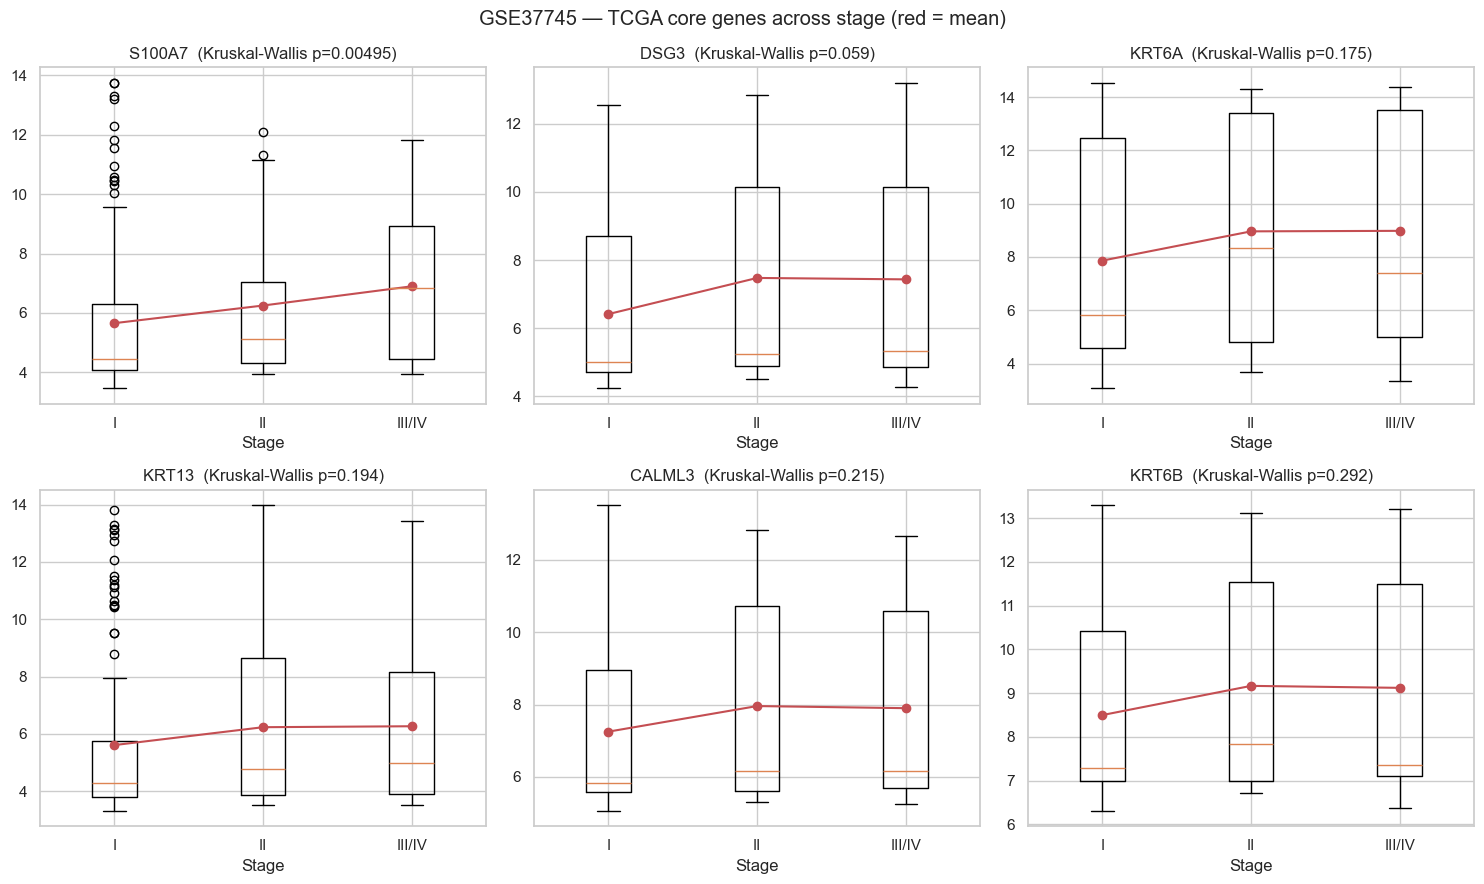

Dunn post-hoc (FDR-adjusted) for the genes plotted above:

--- S100A7 ---
             I      II  III/IV
I       1.0000  0.0366  0.0157
II      0.0366  1.0000  0.5586
III/IV  0.0157  0.5586  1.0000

--- DSG3 ---
             I      II  III/IV
I       1.0000  0.1164  0.1164
II      0.1164  1.0000  0.9759
III/IV  0.1164  0.9759  1.0000

--- KRT6A ---
             I      II  III/IV
I       1.0000  0.2259  0.2259
II      0.2259  1.0000  0.9051
III/IV  0.2259  0.9051  1.0000

--- KRT13 ---
             I      II  III/IV
I       1.0000  0.3271  0.3271
II      0.3271  1.0000  0.7257
III/IV  0.3271  0.7257  1.0000

--- CALML3 ---
             I      II  III/IV
I       1.0000  0.2933  0.2933
II      0.2933  1.0000  0.9739
III/IV  0.2933  0.9739  1.0000

--- KRT6B ---
            I      II  III/IV
I       1.000  0.3570  0.3570
II      0.357  1.0000  0.9967
III/IV  0.357  0.9967  1.0000


In [18]:
plot_genes = stage_tcga_core.head(6)["gene"].tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, g in zip(axes.flatten(), plot_genes):
    data = [X.loc[stage[stage == s].index, g].values for s in STAGE_ORDER]
    ax.boxplot(data, tick_labels=STAGE_ORDER)
    ax.plot(range(1, 4), [np.mean(d) for d in data], "o-", color="#C44E52")
    p = stage_tcga_core.set_index("gene").loc[g, "kruskal_p"]
    ax.set_title(f"{g}  (Kruskal-Wallis p={p:.3g})"); ax.set_xlabel("Stage")
for ax in axes.flatten()[len(plot_genes):]:
    ax.axis("off")
plt.suptitle("GSE37745 — TCGA core genes across stage (red = mean)")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/stage_boxplots.png", dpi=150); plt.show()

print("Dunn post-hoc (FDR-adjusted) for the genes plotted above:")
for g in plot_genes:
    d = pd.DataFrame({"expr": X.loc[stage.index, g].values, "stage": stage.values})
    print(f"\n--- {g} ---")
    print(sp.posthoc_dunn(d, val_col="expr", group_col="stage", p_adjust="fdr_bh").round(4))

## 11. Part E — Survival analysis



In [19]:
surv = clin.loc[:, ["OS_days", "OS_event", "age", "stage"]].copy()
surv["stage_numeric"] = surv["stage"].map({"I": 1, "II": 2, "III": 3, "IV": 4})
surv["histology"] = (y.loc[surv.index] == "LUSC").astype(int)
surv = surv.dropna(subset=["OS_days", "OS_event"])
surv = surv[surv["OS_days"] > 0]
print(f"Patients with survival data: {len(surv)} | events (deaths): {int(surv['OS_event'].sum())}")

genes_tcga_rep = [g for g in TCGA_STAGE_TOP6 if g in X.columns]
genes_gse = [g for g in stage_gse_core.head(6)["gene"] if g not in genes_tcga_rep]
SURV_GENES = genes_tcga_rep + genes_gse
print("TCGA stage-top6 genes available:", genes_tcga_rep,
      "| missing:", [g for g in TCGA_STAGE_TOP6 if g not in X.columns])
print("Additional GSE37745 stage-associated core genes:", genes_gse)

uni_rows, cox_rows = [], []
for g in SURV_GENES:
    e = X.loc[surv.index, g]
    high = e >= e.median()
    lr = logrank_test(surv.loc[high, "OS_days"], surv.loc[~high, "OS_days"],
                      surv.loc[high, "OS_event"], surv.loc[~high, "OS_event"])
    uni_rows.append({"gene": g, "logrank_p": lr.p_value})

    d = surv[["OS_days", "OS_event", "stage_numeric", "age", "histology"]].copy()
    d["gene_expr"] = e
    d = d.dropna()
    try:
        cph = CoxPHFitter().fit(d, duration_col="OS_days", event_col="OS_event", strata=["histology"])
        ci = np.exp(cph.confidence_intervals_.loc["gene_expr"])
        cox_rows.append({"gene": g, "n": len(d), "HR": float(np.exp(cph.params_["gene_expr"])),
                         "CI_low": float(ci.iloc[0]), "CI_high": float(ci.iloc[1]),
                         "cox_p": float(cph.summary.loc["gene_expr", "p"])})
    except Exception as ex:
        print(f"[Cox failed for {g}: {ex}]")

surv_df = pd.DataFrame(uni_rows).merge(pd.DataFrame(cox_rows), on="gene", how="left")
surv_df["cox_p_fdr"] = multipletests(surv_df["cox_p"].fillna(1), method="fdr_bh")[1]
surv_df["source"] = np.where(surv_df["gene"].isin(genes_tcga_rep), "TCGA replication", "GSE37745 pipeline")
print("\n=== Survival results (GSE37745) ===")
print(surv_df.round(4).to_string(index=False))
print(f"\n>>> Univariate significant (p<0.05): {surv_df.loc[surv_df.logrank_p < .05, 'gene'].tolist()}")
print(f">>> Cox significant after FDR: {surv_df.loc[surv_df.cox_p_fdr < .05, 'gene'].tolist()}")
surv_df.to_csv(f"{OUTPUT_DIR}/survival_results.csv", index=False)

Patients with survival data: 172 | events (deaths): 129
TCGA stage-top6 genes available: ['DSG3', 'KRT6A', 'KRT14', 'DSC3'] | missing: ['KRT6C', 'SPRR2A']
Additional GSE37745 stage-associated core genes: ['S100A7', 'SPRR1B', 'SFTA3', 'SPINK1']

=== Survival results (GSE37745) ===
  gene  logrank_p   n     HR  CI_low  CI_high  cox_p  cox_p_fdr            source
  DSG3     0.3054 172 1.0074  0.8860   1.1456 0.9099     0.9099  TCGA replication
 KRT6A     0.3284 172 0.9911  0.9120   1.0772 0.8342     0.9099  TCGA replication
 KRT14     0.7838 172 1.0226  0.9483   1.1026 0.5617     0.9099  TCGA replication
  DSC3     0.7906 172 1.0147  0.8970   1.1480 0.8161     0.9099  TCGA replication
S100A7     0.2463 172 1.0392  0.9513   1.1352 0.3937     0.9099 GSE37745 pipeline
SPRR1B     0.2679 172 0.9782  0.9157   1.0449 0.5120     0.9099 GSE37745 pipeline
 SFTA3     0.0500 172 0.9542  0.8795   1.0353 0.2602     0.9099 GSE37745 pipeline
SPINK1     0.0520 172 0.9906  0.9171   1.0701 0.8113     0.9099

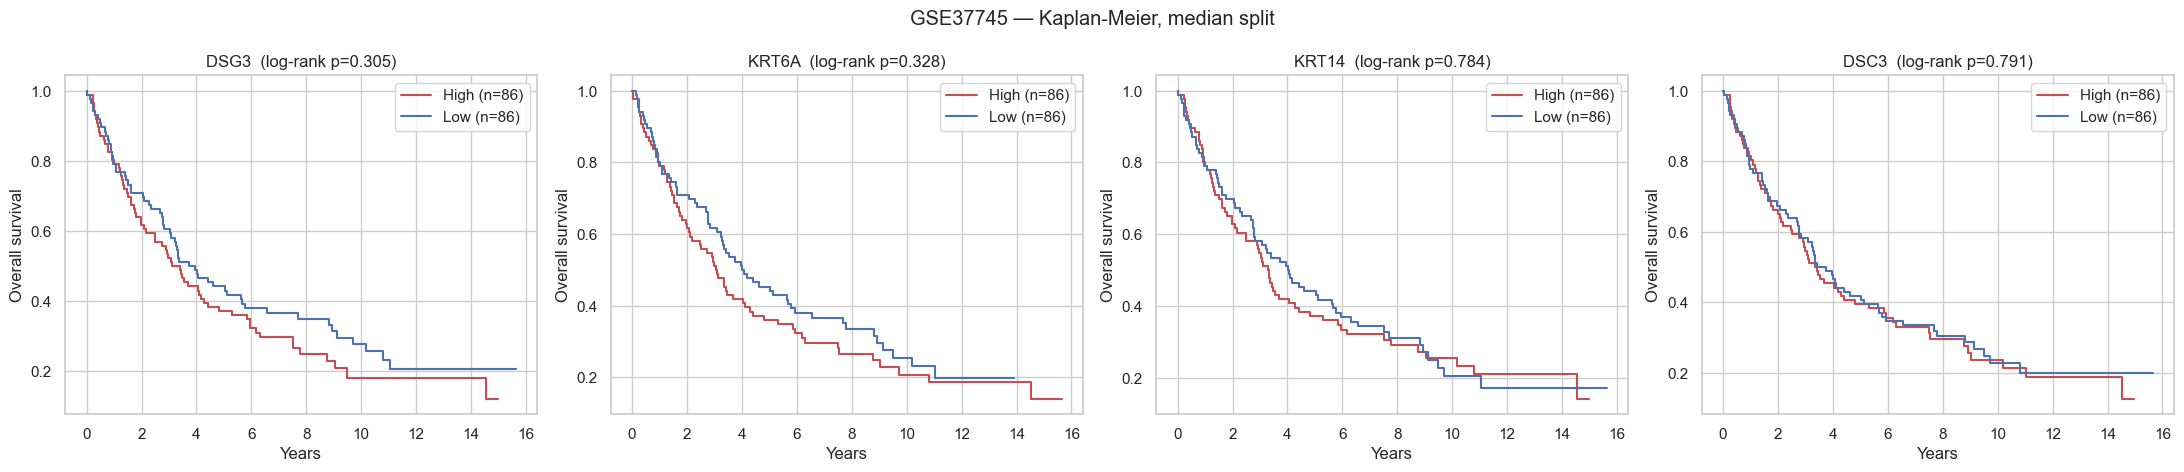

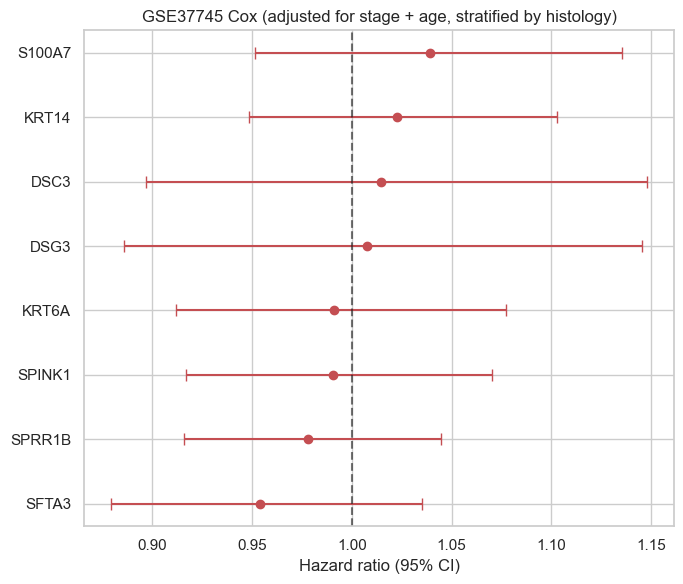

In [20]:
km_genes = genes_tcga_rep[:4] if len(genes_tcga_rep) >= 1 else SURV_GENES[:4]
fig, axes = plt.subplots(1, len(km_genes), figsize=(5.5 * len(km_genes), 4.8), squeeze=False)
for ax, g in zip(axes[0], km_genes):
    e = X.loc[surv.index, g]; high = e >= e.median()
    for mask, lab, col in [(high, "High", "#C44E52"), (~high, "Low", "#4C72B0")]:
        KaplanMeierFitter().fit(surv.loc[mask, "OS_days"] / 365.25, surv.loc[mask, "OS_event"],
                                label=f"{lab} (n={int(mask.sum())})").plot_survival_function(ax=ax, color=col, ci_show=False)
    p = surv_df.set_index("gene").loc[g, "logrank_p"]
    ax.set_title(f"{g}  (log-rank p={p:.3g})"); ax.set_xlabel("Years"); ax.set_ylabel("Overall survival")
plt.suptitle("GSE37745 — Kaplan-Meier, median split")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/km_curves.png", dpi=150); plt.show()

fd = surv_df.dropna(subset=["HR"]).sort_values("HR")
fig, ax = plt.subplots(figsize=(7, 0.5 * len(fd) + 2))
ax.errorbar(fd["HR"], range(len(fd)), xerr=[fd["HR"] - fd["CI_low"], fd["CI_high"] - fd["HR"]],
            fmt="o", color="#C44E52", capsize=4)
ax.axvline(1, color="k", ls="--", alpha=.6)
ax.set_yticks(range(len(fd))); ax.set_yticklabels(fd["gene"])
ax.set_xlabel("Hazard ratio (95% CI)")
ax.set_title("GSE37745 Cox (adjusted for stage + age, stratified by histology)")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/cox_forest_plot.png", dpi=150); plt.show()

## 12. Part F — Pathway enrichment and druggability 

                  Gene_set                                                                  Term  Adjusted P-value                                              Genes
GO_Biological_Process_2023                Negative Regulation Of Peptidase Activity (GO:0010466)          0.000136 SERPINB3;SERPINB4;CSTA;SERPINB2;SERPINB13;SERPINB5
GO_Biological_Process_2023                                             Fibrinolysis (GO:0042730)          0.000136                               FGB;FGA;SERPINB2;FGG
GO_Biological_Process_2023                             Keratinocyte Differentiation (GO:0030216)          0.000349                    SPRR3;CSTA;SPRR2B;SPRR1B;S100A7
GO_Biological_Process_2023                                    Epidermis Development (GO:0008544)          0.000539              SPRR3;KRT5;SPRR2B;PTHLH;SPRR1B;S100A7
GO_Biological_Process_2023                                   Plasminogen Activation (GO:0031639)          0.000619                                        FGB;FGA;FGG
GO_B

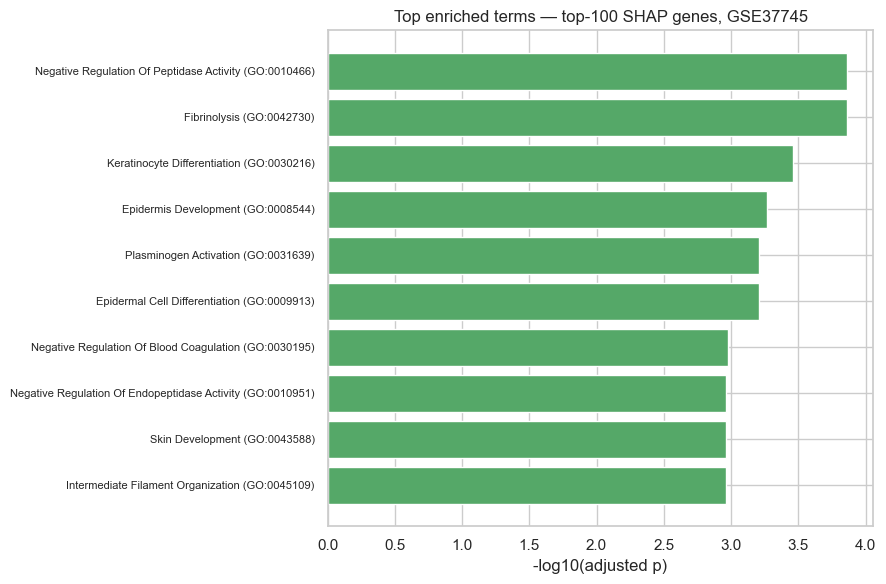

In [21]:
top_100 = list(shap_importance_df["gene"].head(100))
try:
    import gseapy as gp
except ImportError:
    try:
        _pip("gseapy"); import gseapy as gp
    except Exception:
        gp = None
try:
    enr = gp.enrichr(gene_list=top_100, gene_sets=["GO_Biological_Process_2023", "KEGG_2021_Human"],
                     organism="human", outdir=None)
    enrich_results = enr.results.sort_values("Adjusted P-value")
    print(enrich_results[["Gene_set", "Term", "Adjusted P-value", "Genes"]].head(15).to_string(index=False))
    enrich_results.to_csv(f"{OUTPUT_DIR}/pathway_enrichment.csv", index=False)
    t = enrich_results.head(10)
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(range(len(t)), -np.log10(t["Adjusted P-value"]), color="#55A868")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t["Term"], fontsize=8); ax.invert_yaxis()
    ax.set_xlabel("-log10(adjusted p)"); ax.set_title("Top enriched terms — top-100 SHAP genes, GSE37745")
    plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/pathway_enrichment.png", dpi=150); plt.show()
except Exception as e:
    print(f"[Enrichr failed: {e}] Paste this list at https://maayanlab.cloud/Enrichr/ :")
    print(top_100)

In [22]:
import requests
top_20 = list(shap_importance_df["gene"].head(20))
query = """
query($geneNames: [String!]) {
  genes(names: $geneNames) { nodes { name interactions { drug { name } interactionScore } } }
}"""
try:
    r = requests.post("https://dgidb.org/api/graphql",
                      json={"query": query, "variables": {"geneNames": top_20}}, timeout=30)
    r.raise_for_status(); data = r.json()
    if "errors" in data:
        raise ValueError(data["errors"])
    druggable_df = pd.DataFrame([{"gene": n["name"], "n_known_drugs": len(n["interactions"]),
                                  "example_drugs": ", ".join(sorted({i["drug"]["name"] for i in n["interactions"]})[:5])}
                                 for n in data["data"]["genes"]["nodes"]]).sort_values("n_known_drugs", ascending=False)
    print(druggable_df.to_string(index=False))
    druggable_df.to_csv(f"{OUTPUT_DIR}/druggability.csv", index=False)
    print(f"\n>>> {(druggable_df.n_known_drugs > 0).sum()} of the top 20 genes have a known drug interaction.")
except Exception as e:
    print(f"[DGIdb failed: {e}] Gene list: {top_20}")

     gene  n_known_drugs                                                   example_drugs
    NTRK2             65              ALISERTIB, ALTIRATINIB, AST-487, AZD-6918, AZD1332
      FGG              9 ABCIXIMAB, ALFIMEPRASE, ANCROD, EPTIFIBATIDE, FIBRINOGEN, HUMAN
   SPINK1              2                                      ASPARAGINASE, PEGASPARGASE
    KRT6A              1                                                           TD101
 SERPINB3              1                                        THERAPEUTIC GONADOTROPIN
   BPIFB1              0                                                                
    SFTA2              0                                                                
     TP63              0                                                                
     KRT5              0                                                                
   S100A7              0                                                                
    CLCA2            

## 13. Final comparison — TCGA vs GSE37745 (table for the paper)

In [23]:
def fmt_pm(m, s, pct=True):
    return f"{m*100:.2f}% ± {s*100:.2f}%" if pct else f"{m:.4f} ± {s:.4f}"

comparison = pd.DataFrame([
    ["Samples (LUAD / LUSC)", "1,017 (515 / 502)", f"{len(y)} ({int((y=='LUAD').sum())} / {int((y=='LUSC').sum())})"],
    ["Platform", "RNA-seq (Illumina HiSeq)", "Microarray (Affymetrix GPL570)"],
    ["Best model (7-model comparison)", TCGA_REF["winning_model"], WINNING_MODEL],
    ["Final accuracy (30 splits)", fmt_pm(TCGA_REF["final_acc"], TCGA_REF["final_acc_sd"]), fmt_pm(mean_acc, std_acc)],
    ["Final AUC (30 splits)", fmt_pm(TCGA_REF["final_auc"], TCGA_REF["final_auc_sd"], False), fmt_pm(mean_auc, std_auc, False)],
    ["Core-stable SHAP genes", str(TCGA_REF["n_core_stable"]), str(len(GSE_CORE))],
    ["Core genes that are established markers", f"{TCGA_REF['n_core_known_markers']}/{TCGA_REF['n_core_stable']}",
     f"{len(known_core)}/{len(GSE_CORE)}"],
    ["Core-stable genes shared with TCGA", "—", f"{len(shared)}/{len(tcga_available)} ({', '.join(shared)}); permutation p = {p_perm:.3g}"],
    ["TCGA core genes in GSE top 1% of SHAP", "—", f"{int(rep_df['in_top_1pct'].sum())}/{len(rep_df)}"],
    ["Stage-associated core genes (p<0.05)", TCGA_REF["stage_sig"],
     f"{(stage_gse_core['kruskal_p'] < .05).sum()}/{len(stage_gse_core)} (GSE core); "
     f"{(stage_tcga_core['kruskal_p'] < .05).sum()}/{len(stage_tcga_core)} (TCGA core)"],
    ["Univariate survival-significant genes", TCGA_REF["univariate_sig"],
     ", ".join(surv_df.loc[surv_df.logrank_p < .05, "gene"]) or "none"],
    ["Cox-significant after FDR", TCGA_REF["cox_fdr_sig"],
     f"{(surv_df.cox_p_fdr < .05).sum()}/{len(surv_df)}"],
], columns=["Pipeline output", "TCGA (discovery)", "GSE37745 (independent replication)"])

pd.set_option("display.max_colwidth", 80)
print(comparison.to_string(index=False))
comparison.to_csv(f"{OUTPUT_DIR}/TCGA_vs_GSE37745_comparison.csv", index=False)
print(f"\nAll outputs saved in: {OUTPUT_DIR}/")

                        Pipeline output         TCGA (discovery)                                         GSE37745 (independent replication)
                  Samples (LUAD / LUSC)        1,017 (515 / 502)                                                             172 (106 / 66)
                               Platform RNA-seq (Illumina HiSeq)                                             Microarray (Affymetrix GPL570)
        Best model (7-model comparison)       LogisticRegression                                                         LogisticRegression
             Final accuracy (30 splits)           95.69% ± 1.73%                                                             95.19% ± 4.48%
                  Final AUC (30 splits)          0.9884 ± 0.0080                                                            0.9844 ± 0.0297
                 Core-stable SHAP genes                       15                                                                         12
Core genes that are 